In [48]:
#그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler


In [49]:
# 데이터 전처리 완료
perch_length = np.array(
    [8.4, 13.7, 15.0, 16.2, 17.4, 18.0, 18.7, 19.0, 19.6, 20.0,
    21.0, 21.0, 21.0, 21.3, 22.0, 22.0, 22.0, 22.0, 22.0, 22.5,
    22.5, 22.7, 23.0, 23.5, 24.0, 24.0, 24.6, 25.0, 25.6, 26.5,
    27.3, 27.5, 27.5, 27.5, 28.0, 28.7, 30.0, 32.8, 34.5, 35.0,
    36.5, 36.0, 37.0, 37.0, 39.0, 39.0, 39.0, 40.0, 40.0, 40.0,
    40.0, 42.0, 43.0, 43.0, 43.5, 44.0]
    )
perch_weight = np.array(
    [5.9, 32.0, 40.0, 51.5, 70.0, 100.0, 78.0, 80.0, 85.0, 85.0,
    110.0, 115.0, 125.0, 130.0, 120.0, 120.0, 130.0, 135.0, 110.0,
    130.0, 150.0, 145.0, 150.0, 170.0, 225.0, 145.0, 188.0, 180.0,
    197.0, 218.0, 300.0, 260.0, 265.0, 250.0, 250.0, 300.0, 320.0,
    514.0, 556.0, 840.0, 685.0, 700.0, 700.0, 690.0, 900.0, 650.0,
    820.0, 850.0, 900.0, 1015.0, 820.0, 1100.0, 1000.0, 1100.0,
    1000.0, 1000.0]
    )

In [50]:
train_data,test_data,train_label,test_label = train_test_split(perch_length,perch_weight)

In [51]:
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
test_data

array([[23. ],
       [18.7],
       [22. ],
       [44. ],
       [ 8.4],
       [27.5],
       [30. ],
       [32.8],
       [37. ],
       [26.5],
       [23.5],
       [22.7],
       [21. ],
       [36.5]])

In [ ]:
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))


In [58]:
lr = LinearRegression()
lr.fit(train_poly,train_label)

predict = lr.predict(test_poly)
print('무게예측 : ',predict)
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
print("train 정확도 : ",score)
print("test 정확도 : ",score2)

무게예측 :  [ 156.95402635   72.60251425  133.77824501 1141.92652147   32.74063306
  287.93867205  379.58220326  498.2283507   707.9063683   255.05611629
  169.35081489  149.77480055  112.75952465  680.94941813]
train 정확도 :  0.9710684740616871
test 정확도 :  0.9752850434758009


In [59]:
input1 = 25
result = lr.predict([[input1**2,input1]])
print('예측무게 : ',result)

예측무게 :  [209.77677198]


In [60]:
print(lr.coef_,lr.intercept_)

[  1.07853049 -25.35809076] 169.64748397919715


In [61]:
point = np.arange(5,51)
point

array([ 5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21,
       22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38,
       39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50])

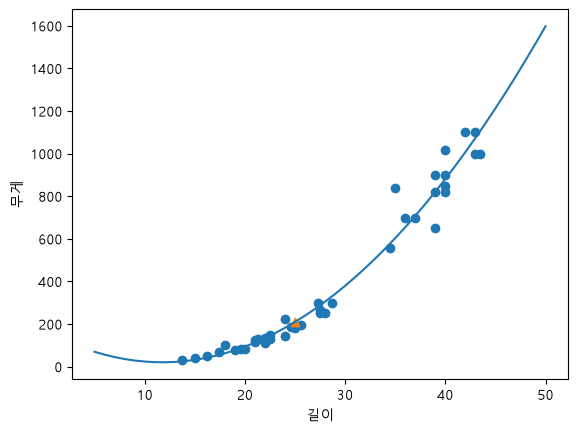

In [65]:
plt.scatter(train_data,train_label)
plt.scatter(input1,result,marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()